# HCWF blending demo: Ethiopia

A **blend** turns the onset climatology and the onset dates of the forecast models into probabilities that the onset falls in week 1, 2, 3, 4 or later after an issue date. This notebook trains one (cross-validated against climatology baselines), then applies it to a live 2025 forecast.

Steps: 1 setup and data slice, 2 blend config and `hcwf.check`, 3 train, 4 evaluation, 5 live forecast, 6 what else.
Models: AIFS_v2 and GraphCast (deterministic). Training years 2012-2023, 2024 held out. Runtime: about 1-2 minutes.

CLI equivalents: `hcwf-run -p blend.yaml` trains, `hcwf-run forecast trained.blend --forecast MODEL=PATH` applies.

## 1. Setup and data slice
One variable (`DATA`) points at the data.

In [1]:
%matplotlib inline
import os
from pathlib import Path

REGION = "ethiopia"

# ONE place that says where the data are: set HCWF_DEMO_DATA, or keep the repo's data/ folder
# (found by looking upward from the folder this notebook runs in). It must hold <region>/obs.zarr
# and <region>/models/<MODEL>.zarr.
DATA = Path(os.environ.get("HCWF_DEMO_DATA")
            or next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / REGION).is_dir())).expanduser()
OBS = DATA / REGION / "obs.zarr"
MODELS = DATA / REGION / "models"
print("data root:", DATA)

import copy
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

import hcwf
from hcwf.api import forecast
from hcwf.blend import TrainedBlend

plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (9, 3.5)})
warnings.filterwarnings("ignore", message=".*negative values")   # AI forecasts: small negative rain, set to 0

data root: /home/hcwf/code/ROMP/.claude/worktrees/agent-a38c2e4dd2829dbd0/data


The blend trainer and the forecast command read **NetCDF files, one per year with the year in the name**, not zarr stores (a gap, noted in the README). So this cell exports a slice of the stores to `blend_data/` next to the notebook (git-ignored): observations from 1998, forecasts for 2012-2025 with the first 40 lead days, over the whole Ethiopia domain. Existing files are reused.

In [2]:
WORK = Path("blend_data")
BOX = None   # ((lat0, lat1), (lon0, lon1)) or None


def export(store, path, *, time, lead_days=None, box=None):
    """Write a time slice (and optionally the first lead days and a lat-lon box) of a zarr store as NetCDF."""
    ds = xr.open_zarr(store)
    ds.attrs.clear()
    for variable in ds.variables.values():
        variable.encoding = {}
    lat = next(d for d in ds.dims if d.lower().startswith("lat"))
    lon = next(d for d in ds.dims if d.lower().startswith("lon"))
    time_dim = next(d for d in ds.dims if d.lower() == "time")
    if lead_days:
        ds = ds.isel(prediction_timedelta_daily=slice(0, lead_days))
    if box:
        (lat0, lat1), (lon0, lon1) = box
        ds = ds.isel({lat: np.flatnonzero((ds[lat] >= lat0) & (ds[lat] <= lat1)),
                      lon: np.flatnonzero((ds[lon] >= lon0) & (ds[lon] <= lon1))})
    path.parent.mkdir(parents=True, exist_ok=True)
    ds.sel({time_dim: time}).to_netcdf(path)


for year in range(1998, 2026):
    if not (WORK / "obs" / f"{year}.nc").exists():
        export(OBS, WORK / "obs" / f"{year}.nc", time=str(year), box=BOX)
for name in ["AIFS_v2", "graphcast"]:
    for year in range(2012, 2026):
        if not (WORK / name / f"{year}.nc").exists():
            export(MODELS / f"{name}.zarr", WORK / name / f"{year}.nc", time=str(year), lead_days=40, box=BOX)
print(sorted(path.name for path in WORK.iterdir()))

['AIFS_v2', 'graphcast', 'obs']


## 2. The blend config
The same dict as a benchmark, plus a `blend:` section (a config with `blend:` trains instead of benchmarking):

* `observations`, `models`: the yearly files just exported (`paths` are globs; any number of files per year).
* `evaluation`: the years of the issue dates (2012-2024).
* `blend.years`: `training` (fitted), `cv_holdout` (scored by **leave-one-year-out** cross-validation), `true_holdout` (scored, never fitted).
* `blend.formulas`: the recipe, a formula over features: `prob_clim_qx` (the climatology's probability) plus one term per model. `icpac` has no named rainfall threshold, so the models enter through their own onset probabilities (`<model>_p_onset_qx`: the share of weeks in which the model's rainfall shows an onset).
* `blend.models`: per model, the lead days read (1-40) and optional rain predictors.
* Units are the grid cells of the files (the default for a blend). Onset definition and day boundary come from the region.

In [3]:
cfg = {
    "project_name": "Ethiopia blend demo",
    "region": REGION,
    "observations": {"paths": [str(WORK / "obs" / "*.nc")]},
    "models": [
        {"name": "aifs", "paths": [str(WORK / "AIFS_v2" / "*.nc")]},
        {"name": "graphcast", "paths": [str(WORK / "graphcast" / "*.nc")]},
    ],
    "evaluation": {"start_date": [2012, 5, 1], "end_date": [2024, 8, 31]},
    "blend": {
        "years": {"training": "2012:2023", "cv_holdout": "2012:2023", "true_holdout": 2024},
        "fixed_cutoff": "06-10",
        "formulas": {"blended_model": "outcome ~ prob_clim_qx + aifs_p_onset_qx + graphcast_p_onset_qx"},
        "models": {
            "aifs": {"lead_days": [1, 40]},
            "graphcast": {"lead_days": [1, 40]},
        },
    },
}

`hcwf.check` plans the blend without training: its `== Blend ==` block lists outcomes, years, formulas, the cutoff, and the artifact folder.

In [4]:
plan = hcwf.check(cfg, overwrite=True)   # plan as for a re-run: the run folder may already exist
print("ok:", plan.ok, "| errors:", plan.errors)
text = plan.text()
for section in text.split("\n== "):
    if section.startswith(("Settings", "Blend")):
        for line in ("== " + section).splitlines()[:22]:
            print(line[:170])

ok: True | errors: []
== Settings ==
config file     : None
region          : ethiopia  [run config]
first date      : (2012, 5, 1)  [run config]
last date       : (2024, 8, 31)  [run config]
init weekdays   : (0, 3)  [default]
climatology from: 1998  [region default]
climatology to  : 2024  [region default]
lead windows    : ((1, 15), (16, 30))  [default]
tolerances (days): (3, 5)  [default]
max forecast day: 30  [default]
day bins        : ((1, 5), (6, 10), (11, 15), (16, 20), (21, 25), (26, 30))  [default]
ensemble        : False  [default]
members         : All  [default]
reference       : climatology  [default]
climatology_cv  : leave_one_year_out  [default]
ensemble onset share: 0.5  [default]
models          : aifs, graphcast
Onset definition : icpac v1 (draft)  [region default (ethiopia)]
Season           : main  [the definition's only season]
Threshold years  : 1998-2024  [region default (ethiopia)]
Day boundary     : 00 UTC, labelled by start  [region default (ethiopia)]
== B

## 3. Train
`hcwf.run` on a blend config builds the weekly features from observed and forecast onsets, cross-validates the formula and the baselines, fits the operational model on all training years and (with `write=True`) writes the blend folder. (`warning:` lines about negative values are small negative rain amounts of the AI models, set to 0 by hcwf.)

In [5]:
trained = hcwf.run(cfg, write=True, overwrite=True, quiet=True)
print("run folder:", trained.folder)
print(type(trained.blend).__name__, "| cross-validated formulas:", list(trained.blend.evaluation.formulas))

run folder: /home/hcwf/code/ROMP/.claude/worktrees/agent-a38c2e4dd2829dbd0/demo/ethiopia/runs/ethiopia_icpac_2012-2024_9a47
TrainingResult | cross-validated formulas: ['blended_model']


## 4. Evaluation
`trained.blend.evaluation` holds the score tables as DataFrames; each is also a CSV in `blend/`. Skill is relative to the climatology baselines (positive = better); `rps` is the ranked probability score over the five week bins.

In [6]:
evaluation = trained.blend.evaluation
pooled = evaluation.pooled.set_index("model")
display(pooled[["brier", "rps", "auc", "brier_skill", "rps_skill"]].round(3))

,brier,rps,auc,brier_skill,rps_skill
model,,,,,
blended_model,0.596,0.634,0.802,0.072,0.270
unc_clim_raw,0.642,0.868,0.769,0.000,0.000
clim_raw,0.611,0.660,0.791,0.048,0.240
aifs_fixed_cutoff_raw,1.069,1.357,0.666,-0.665,-0.563
aifs_calibrated_fixed_cutoff,0.702,0.834,0.693,-0.093,0.039
graphcast_fixed_cutoff_raw,1.051,1.310,0.672,-0.637,-0.509
graphcast_calibrated_fixed_cutoff,0.696,0.823,0.697,-0.084,0.053


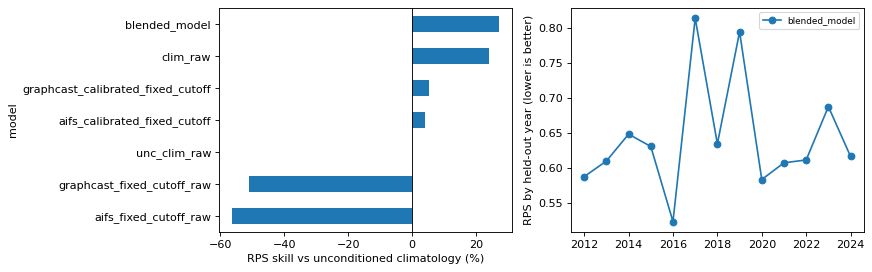

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
(pooled["rps_skill"] * 100).sort_values().plot.barh(ax=axes[0])
axes[0].axvline(0, color="k", lw=0.8); axes[0].set_xlabel("RPS skill vs unconditioned climatology (%)")
yearly = evaluation.yearly
for model, part in yearly.groupby("model"):   # the models with cross-validated predictions
    axes[1].plot(part["year"], part["rps"], "o-", label=model)
axes[1].set_ylabel("RPS by held-out year (lower is better)"); axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

The files of the `blend/` folder (names follow the former `onset_blending` contract). `<tag>` encodes the cutoff mode and years.

In [8]:
blend_dir = trained.folder / "blend"
for path in sorted(blend_dir.iterdir()):
    print(f"{path.stat().st_size / 1e3:9.0f} kB  {path.name}")
display(pd.read_csv(next(blend_dir.glob("summary_models_<tag>.csv".replace("<tag>", "fixed_cutoff_*")))).head(3).round(3))

       24 kB  coefs_blended_model_global_fixed_cutoff_2012_2024.nc
    25744 kB  cv_preds_blended_model_global_fixed_cutoff_2012_2024.nc
        1 kB  formula_sample_support_fixed_cutoff_2012_2024.json
     1120 kB  summary_models_fixed_cutoff_2012_2024.csv
        3 kB  summary_models_pooled_fixed_cutoff_2012_2024.csv
      150 kB  trained.blend
        1 kB  yearly_metrics_global_fixed_cutoff_2012_2024.csv


,id,brier,rps,auc,n,lat,lon,pietra,brier_week1,brier_week2,brier_week3,brier_week4,brier_later,auc_week1,auc_week2,auc_week3,auc_week4,auc_later,model,cv_method
0,10.25_33,0.721,0.720,0.708,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,blended_model,global
1,10.25_33.25,0.766,0.814,0.669,138,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,blended_model,global
2,10.25_33.5,0.786,0.879,0.632,107,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,blended_model,global


`trained.blend` (a `TrainingResult`) has the evaluation, and `trained.blend.model` is the operational model. The file `trained.blend` is the self-contained product: run config, definition, recipe, models, observed onsets, units, thresholds and reference. It loads back as a `TrainedBlend`.

In [9]:
blend_file = blend_dir / "trained.blend"
loaded = TrainedBlend.load(blend_file)
print(type(loaded).__name__, "| models:", [m for m in loaded.recipe.model_names], "| definition:", loaded.definition_text[:90], "...")

TrainedBlend | models: ['aifs', 'graphcast'] | definition: id: icpac
version: 1
title: ICPAC operational seasonal rainfall onset (JJAS season)
citati ...


## 5. Live forecast
Apply the trained blend to the forecasts of one 2025 issue date (2025-06-09, outside the training years). `forecast` takes one file (or glob) per trained model, so the issue is exported from the zarr stores to a single NetCDF each (see the note in step 1). The forecast must have the units, grid spacing and issue hour the blend was trained on; every difference is reported before anything is read.

In [10]:
ISSUE = "2025-06-09"
live = {}
for name, store in {"aifs": "AIFS_v2", "graphcast": "graphcast"}.items():
    live[name] = WORK / "live" / f"{name}_{ISSUE}.nc"
    export(MODELS / f"{store}.zarr", live[name], time=[ISSUE], lead_days=40, box=BOX)

fc = forecast(blend_file, {name: str(path) for name, path in live.items()})
print("issue dates:", fc.issue_dates)
fc.weekly

issue dates: [datetime.date(2025, 6, 9)]


<xarray.Dataset> Size: 167kB
Dimensions:          (time: 1, id: 1495)
Coordinates:
  * time             (time) datetime64[s] 8B 2025-06-09
  * id               (id) object 12kB '10.25_33' '10.25_33.25' ... '9_43.75'
Data variables: (12/13)
    cv_week1         (time, id) float64 12kB 0.2079 0.1417 ... 0.1312 0.1474
    cv_week2         (time, id) float64 12kB 0.1651 0.1393 ... 0.1306 0.1425
    cv_week3         (time, id) float64 12kB 0.1718 0.1539 ... 0.1367 0.1469
    cv_week4         (time, id) float64 12kB 0.167 0.1401 ... 0.1048 0.1131
    cv_later         (time, id) float64 12kB 0.2881 0.425 ... 0.4967 0.4501
    clim_week1       (time, id) float64 12kB 0.1848 0.1137 ... 0.09526 0.1217
    ...               ...
    clim_week3       (time, id) float64 12kB 0.1569 0.1476 ... 0.07753 0.09962
    clim_week4       (time, id) float64 12kB 0.1546 0.1551 ... 0.07057 0.08814
    clim_later       (time, id) float64 12kB 0.3345 0.4511 ... 0.6706 0.5795
    lat              (id) float64 12kB 10.25 10.25 10.25 10.25 ... 9.0 9.0 9.0
    lon              (id) float64 12kB 33.0 33.25 33.5 ... 43.25 43.5 43.75
    onset_threshold  (id) float64 12kB nan nan nan nan nan ... nan nan nan nan

`fc.weekly_table` is the contract table (one row per unit and issue: the blend's `cv_week1..4`, `cv_later` and the climatology's `clim_*`). The map shows the blend's probability of onset in each week, and its change against climatology.

In [11]:
display(fc.weekly_table.head(3).round(3))

,id,time,onset_threshold,lat,lon,cv_week1,cv_week2,cv_week3,cv_week4,cv_later,clim_week1,clim_week2,clim_week3,clim_week4,clim_later
0,10.25_33,2025-06-09,NaN,10.25,33.00,0.208,0.165,0.172,0.167,0.288,0.185,0.169,0.157,0.155,0.335
1,10.25_33.25,2025-06-09,NaN,10.25,33.25,0.142,0.139,0.154,0.140,0.425,0.114,0.133,0.148,0.155,0.451
2,10.25_33.5,2025-06-09,NaN,10.25,33.50,0.190,0.170,0.168,0.129,0.342,0.214,0.200,0.173,0.142,0.271


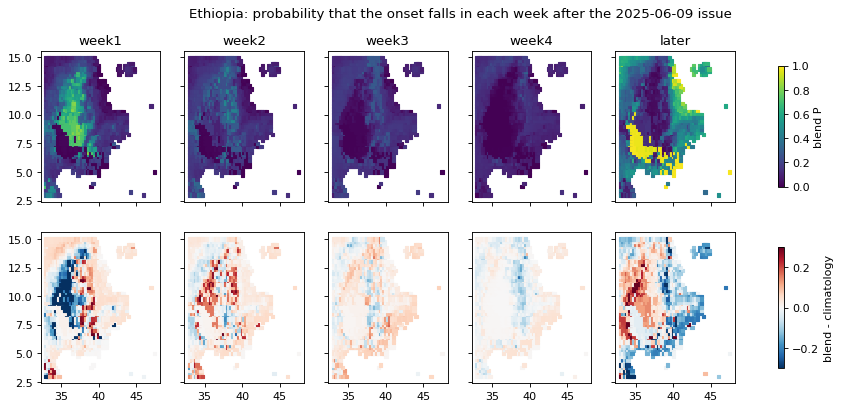

In [12]:
weeks = ["cv_week1", "cv_week2", "cv_week3", "cv_week4", "cv_later"]
data = fc.weekly.isel(time=0)
fig, axes = plt.subplots(2, 5, figsize=(14, 5.4), sharex=True, sharey=True)
for col, name in enumerate(weeks):
    blend_p = data[name]
    for row, (values, cmap, vmin, vmax, label) in enumerate([
            (blend_p, "viridis", 0, 1, "blend P"),
            (blend_p - data[name.replace("cv_", "clim_")], "RdBu_r", -0.3, 0.3, "blend - climatology")]):
        ax = axes[row, col]
        points = ax.scatter(data["lon"], data["lat"], c=values, s=9, marker="s", cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(name.replace("cv_", "") if row == 0 else "")
        if col == len(weeks) - 1:
            fig.colorbar(points, ax=axes[row], shrink=0.8, label=label)
fig.suptitle(f"Ethiopia: probability that the onset falls in each week after the {ISSUE} issue")
plt.show()

## 6. What else
**Save and share.** `forecast(..., write=True)` (or the CLI) writes `blended_forecast_probabilities.csv`, the contract file; `netcdf=True` adds a NetCDF twin. A `trained.blend` can be copied anywhere and loaded with `TrainedBlend.load`; `loaded.forecast({...})` is the method behind `forecast`.

In [13]:
out = forecast(blend_file, {name: str(path) for name, path in live.items()}, write=True, netcdf=True,
               output=trained.folder / "forecasts" / ISSUE)
print("written to", out.folder)
for path in sorted(out.folder.iterdir()):
    print(f"{path.stat().st_size / 1e3:9.0f} kB  {path.name}")
same = loaded.forecast({name: str(path) for name, path in live.items()})
print("same probabilities from TrainedBlend.forecast:", np.allclose(same.weekly["cv_week1"], fc.weekly["cv_week1"]))

written to /home/hcwf/code/ROMP/.claude/worktrees/agent-a38c2e4dd2829dbd0/demo/ethiopia/runs/ethiopia_icpac_2012-2024_9a47/forecasts/2025-06-09
      325 kB  blended_forecast_probabilities.csv
      261 kB  blended_forecast_probabilities.nc


same probabilities from TrainedBlend.forecast: True


The same from the shell (several `--forecast MODEL=PATH`, one per trained model; `-o` is a new or empty folder):

```bash
hcwf-run -p blend.yaml                                   # train (the config above, as YAML)
hcwf-run forecast runs/<run>/blend/trained.blend \
    --forecast aifs=live/aifs_2025-06-09.nc --forecast graphcast=live/graphcast_2025-06-09.nc \
    --issue-date 2025-06-09 --netcdf -o forecasts/2025-06-09
```
Blend keys, units on polygons and several blends in one go: `docs/blending.md`.